In [1]:

import pandas as pd

data = pd.read_excel("Marks (2).xlsx")

print(data.head())


       ID Division  Quiz  Practical  Project  Final
0  H00247      EDU    84         67     69.6     67
1  H00258      HLT    74         68     67.0     73
2  H00269      ENG    88         86     75.6     74
3  H00224      EDU    74         71     65.8     71
4  H00269      EDU    22         65     66.8     78


In [3]:

data["Total"] = (0.1 * data["Quiz"] +
                 0.3 * data["Practical"] +
                 0.3 * data["Project"] +
                 0.3 * data["Final"])

X = data[["Quiz", "Practical", "Project", "Final"]]
y = data["Total"]

print("Independent Variables (X):")
print(X.head())

print("Dependent Variable (y):")
print(y.head())


Independent Variables (X):
   Quiz  Practical  Project  Final
0    84         67     69.6     67
1    74         68     67.0     73
2    88         86     75.6     74
3    74         71     65.8     71
4    22         65     66.8     78
Dependent Variable (y):
0    69.48
1    69.80
2    79.48
3    69.74
4    65.14
Name: Total, dtype: float64


In [4]:
print(data.isnull().sum())
print(data.duplicated().sum())

ID           0
Division     0
Quiz         0
Practical    0
Project      0
Final        0
Total        0
dtype: int64
0


In [5]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training:", X_train.shape)
print("Testing:", X_test.shape)


Training: (18, 4)
Testing: (5, 4)


In [6]:
cols = ["Quiz", "Practical", "Project", "Final"]
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1
low = Q1 - 1.5 * IQR
high = Q3 + 1.5 * IQR
outliers = ((X < low) | (X > high)).any(axis=1)
print("Outliers:", outliers.sum())
print(data[outliers])


Outliers: 1
       ID Division  Quiz  Practical  Project  Final  Total
4  H00269      EDU    22         65     66.8     78  65.14


In [7]:
data_clean = data.drop(data[outliers].index)
X = data_clean[["Quiz", "Practical", "Project", "Final"]]
y = data_clean["Total"]
print("Rows after cleaning:", len(data_clean))

Rows after cleaning: 22


In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (17, 4)
Testing: (5, 4)


In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("R2:", r2_score(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))

R2: 1.0
MSE: 4.0389678347315804e-28


In [10]:
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree=2)
X_poly_train = poly.fit_transform(X_train)
X_poly_test = poly.transform(X_test)
poly_model = LinearRegression()
poly_model.fit(X_poly_train, y_train)
poly_pred = poly_model.predict(X_poly_test)
print("R2:", r2_score(y_test, poly_pred))
print("MSE:", mean_squared_error(y_test, poly_pred))

R2: 1.0
MSE: 6.85008944770476e-26


In [11]:
from sklearn.linear_model import Ridge
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_test)
print("R2:", r2_score(y_test, ridge_pred))
print("MSE:", mean_squared_error(y_test, ridge_pred))

R2: 0.9999992633715351
MSE: 4.4610502699864084e-05


In [12]:
from sklearn.linear_model import Lasso
lasso_model = Lasso(alpha=0.1)
lasso_model.fit(X_train, y_train)
lasso_pred = lasso_model.predict(X_test)
print("R2:", r2_score(y_test, lasso_pred))
print("MSE:", mean_squared_error(y_test, lasso_pred))

R2: 0.9999745422419352
MSE: 0.0015417316041881743


In [13]:
from sklearn.linear_model import ElasticNet
elastic_model = ElasticNet(alpha=0.1, l1_ratio=0.5)
elastic_model.fit(X_train, y_train)
elastic_pred = elastic_model.predict(X_test)
print("R2:", r2_score(y_test, elastic_pred))
print("MSE:", mean_squared_error(y_test, elastic_pred))

R2: 0.9999894867995475
MSE: 0.0006366834564736875


In [14]:
results = pd.DataFrame({
    "Model": ["Linear", "Polynomial", "Ridge", "Lasso", "Elastic Net"],
    "R2": [
        r2_score(y_test, y_pred),
        r2_score(y_test, poly_pred),
        r2_score(y_test, ridge_pred),
        r2_score(y_test, lasso_pred),
        r2_score(y_test, elastic_pred)
    ],
    "MSE": [
        mean_squared_error(y_test, y_pred),
        mean_squared_error(y_test, poly_pred),
        mean_squared_error(y_test, ridge_pred),
        mean_squared_error(y_test, lasso_pred),
        mean_squared_error(y_test, elastic_pred)
    ]
})
print(results)

         Model        R2           MSE
0       Linear  1.000000  4.038968e-28
1   Polynomial  1.000000  6.850089e-26
2        Ridge  0.999999  4.461050e-05
3        Lasso  0.999975  1.541732e-03
4  Elastic Net  0.999989  6.366835e-04


In [15]:
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

Intercept: 2.842170943040401e-14
Coefficients: [0.1 0.3 0.3 0.3]


In [16]:
print("Intercept:", poly_model.intercept_)
print("Coefficients:", poly_model.coef_)
print("Features:", poly.get_feature_names_out(X.columns))

Intercept: 7.389644451905042e-13
Coefficients: [ 0.00000000e+00  1.00000000e-01  3.00000000e-01  3.00000000e-01
  3.00000000e-01 -4.96951469e-19 -1.03577525e-15  3.73434325e-16
  1.87421142e-15 -8.80441837e-16  1.01841828e-15  2.67315337e-17
 -1.54406412e-16 -2.06174759e-15  8.74540089e-16]
Features: ['1' 'Quiz' 'Practical' 'Project' 'Final' 'Quiz^2' 'Quiz Practical'
 'Quiz Project' 'Quiz Final' 'Practical^2' 'Practical Project'
 'Practical Final' 'Project^2' 'Project Final' 'Final^2']


In [17]:
print("Intercept:", ridge_model.intercept_)
print("Coefficients:", ridge_model.coef_)

Intercept: 0.06809630834902691
Coefficients: [0.10007764 0.29988131 0.29966764 0.29945463]


In [18]:
print("Intercept:", lasso_model.intercept_)
print("Coefficients:", lasso_model.coef_)

Intercept: 0.3811281530498434
Coefficients: [0.10002908 0.29932123 0.29830558 0.29714965]


In [19]:
print("Intercept:", elastic_model.intercept_)
print("Coefficients:", elastic_model.coef_)

Intercept: 0.24826450618010654
Coefficients: [0.10007969 0.2995592  0.29887126 0.29811399]


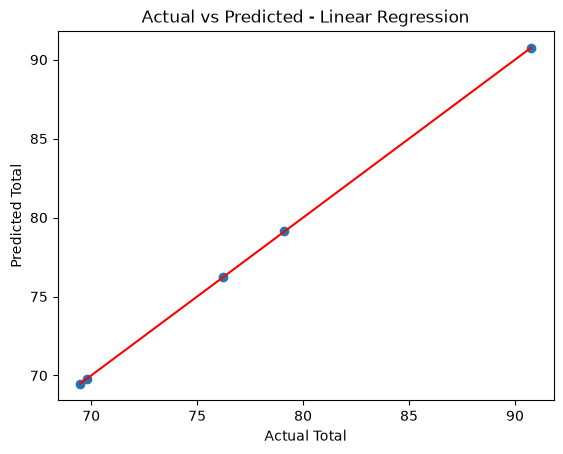

In [20]:
import matplotlib.pyplot as plt
plt.scatter(y_test, y_pred)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], color="red")
plt.xlabel("Actual Total")
plt.ylabel("Predicted Total")
plt.title("Actual vs Predicted - Linear Regression")
plt.show()

In [21]:
data_clean["Result"] = (data_clean["Total"] >= 60).astype(int)
print(data_clean[["Total", "Result"]].head())
print(data_clean["Result"].value_counts())

   Total  Result
0  69.48       1
1  69.80       1
2  79.48       1
3  69.74       1
5  67.72       1
Result
1    22
Name: count, dtype: int64


In [22]:
data_clean["Result"] = (data_clean["Total"] >= 75).astype(int)
print(data_clean[["Total", "Result"]].head())
print(data_clean["Result"].value_counts())

   Total  Result
0  69.48       0
1  69.80       0
2  79.48       1
3  69.74       0
5  67.72       0
Result
0    14
1     8
Name: count, dtype: int64


In [23]:
X = data_clean[["Quiz", "Practical", "Project", "Final"]]
y = data_clean["Result"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training:", X_train.shape)
print("Testing:", X_test.shape)
print("Training categories:")
print(y_train.value_counts())
print("Testing categories:")
print(y_test.value_counts())

Training: (17, 4)
Testing: (5, 4)
Training categories:
Result
0    11
1     6
Name: count, dtype: int64
Testing categories:
Result
0    3
1    2
Name: count, dtype: int64


In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train, y_train)
log_pred = log_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, log_pred))
print("Precision:", precision_score(y_test, log_pred))
print("Recall:", recall_score(y_test, log_pred))
print("F1:", f1_score(y_test, log_pred))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1: 1.0


In [25]:
from sklearn.neighbors import KNeighborsClassifier
knn_model = KNeighborsClassifier(n_neighbors=3)
knn_model.fit(X_train, y_train)
knn_pred = knn_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, knn_pred))
print("Precision:", precision_score(y_test, knn_pred))
print("Recall:", recall_score(y_test, knn_pred))
print("F1:", f1_score(y_test, knn_pred))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1: 1.0


In [26]:
from sklearn.svm import SVC
svm_model = SVC()
svm_model.fit(X_train, y_train)
svm_pred = svm_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, svm_pred))
print("Precision:", precision_score(y_test, svm_pred))
print("Recall:", recall_score(y_test, svm_pred))
print("F1:", f1_score(y_test, svm_pred))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1: 1.0


In [27]:
from sklearn.tree import DecisionTreeClassifier
tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, tree_pred))
print("Precision:", precision_score(y_test, tree_pred))
print("Recall:", recall_score(y_test, tree_pred))
print("F1:", f1_score(y_test, tree_pred))

Accuracy: 0.8
Precision: 0.6666666666666666
Recall: 1.0
F1: 0.8


In [28]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1:", f1_score(y_test, rf_pred))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1: 1.0


In [29]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN", "SVM", "Decision Tree", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, log_pred),
        accuracy_score(y_test, knn_pred),
        accuracy_score(y_test, svm_pred),
        accuracy_score(y_test, tree_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, log_pred),
        precision_score(y_test, knn_pred),
        precision_score(y_test, svm_pred),
        precision_score(y_test, tree_pred),
        precision_score(y_test, rf_pred)
    ],
    "Recall": [
        recall_score(y_test, log_pred),
        recall_score(y_test, knn_pred),
        recall_score(y_test, svm_pred),
        recall_score(y_test, tree_pred),
        recall_score(y_test, rf_pred)
    ],
    "F1": [
        f1_score(y_test, log_pred),
        f1_score(y_test, knn_pred),
        f1_score(y_test, svm_pred),
        f1_score(y_test, tree_pred),
        f1_score(y_test, rf_pred)
    ]
})
print(results)

                 Model  Accuracy  Precision  Recall   F1
0  Logistic Regression       1.0   1.000000     1.0  1.0
1                  KNN       1.0   1.000000     1.0  1.0
2                  SVM       1.0   1.000000     1.0  1.0
3        Decision Tree       0.8   0.666667     1.0  0.8
4        Random Forest       1.0   1.000000     1.0  1.0


In [30]:
pred = rf_model.predict(X)
print("Low (0):", (pred == 0).sum())
print("High (1):", (pred == 1).sum())

Low (0): 14
High (1): 8


C:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, 

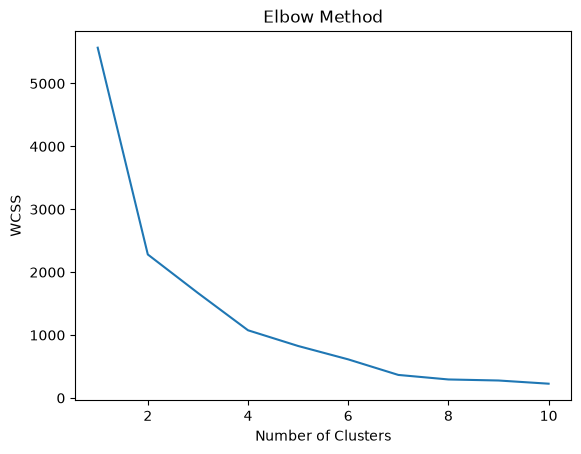

In [31]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
X_cluster = data_clean[["Quiz", "Final"]]
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(X_cluster)
    wcss.append(kmeans.inertia_)
plt.plot(range(1, 11), wcss)
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()

In [32]:
kmeans = KMeans(n_clusters=4, random_state=42)
clusters = kmeans.fit_predict(X_cluster)
print("Cluster labels:")
print(clusters)
print("Number of records in each cluster:")
print(pd.Series(clusters).value_counts().sort_index())

Cluster labels:
[2 2 2 2 3 2 3 1 0 2 3 1 3 2 0 2 1 1 1 2 2 1]
Number of records in each cluster:
0     2
1     6
2    10
3     4
Name: count, dtype: int64


C:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


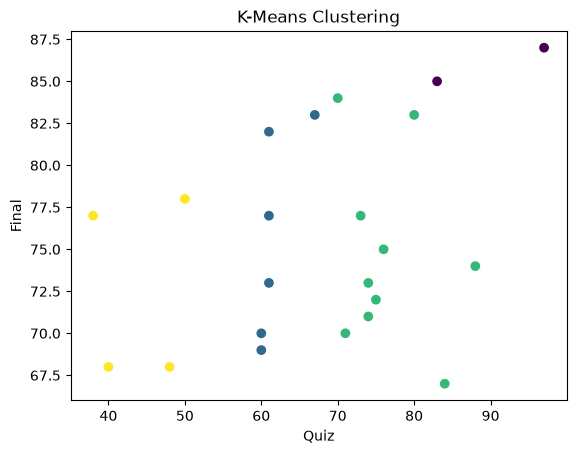

In [33]:
plt.scatter(X_cluster["Quiz"], X_cluster["Final"], c=clusters)
plt.xlabel("Quiz")
plt.ylabel("Final")
plt.title("K-Means Clustering")
plt.show()

In [34]:
data_clean["Cluster"] = clusters
print(data_clean.groupby("Cluster")[["Quiz", "Final"]].mean())

              Quiz      Final
Cluster                      
0        90.000000  86.000000
1        61.666667  75.666667
2        76.500000  74.600000
3        44.000000  72.750000
